# Dataset Discovery

This notebook is meant to highlight the most important characteristics of the given dataset.
</br>
Some listings (e.g. columns, patterns) and data quality checks will be shown.

#### Dataset details
- community of 250 households built using energy consumption and solar generation data
- 200 community members were assigned solar generation | 150 were assigned battery storage system
- each end-user receives two EVs (500)

The dataset is spread on multiple sheets:

In [1]:
import pandas as pd

excel_path = "../data/EC_EV_dataset (fixed error).xlsx"

Extracting some tables from 'General Information' sheet.

In [2]:
# Time of Usage tarrifs
df_tou_rates = pd.read_excel(
    excel_path, sheet_name="General Information", header=None,
    skiprows=27,
    nrows=4,
    usecols="E:G"
)
df_tou_rates.columns = ["Tariff Tier", "<=20.7 kVA", ">20.7kVA"]

df_tou_rates

,Tariff Tier,<=20.7 kVA,>20.7kVA
0,CP (KVA),"<=20,7",">20,7"
1,On-Peak (€),0.2336,0.2982
2,Mid-Peak (€),0.171,0.1623
3,Off-Peak (€),0.1073,0.0953


In [3]:
df_tou_periods = pd.read_excel(
    excel_path, sheet_name="General Information", header=0,
    skiprows=33,
    nrows=3,
    usecols="E:H"
)
df_tou_periods

,Super Off-Peak,Off-Peak,Mid-Peak,On-Peak
0,02:00 - 06:00,00:00 - 02:00,07:00 - 09:30,09:30 - 12:00
1,NaN,06:00 - 07:00,12:00 - 18:30,18:30 - 21:00
2,NaN,NaN,21:00 - 24:00,NaN


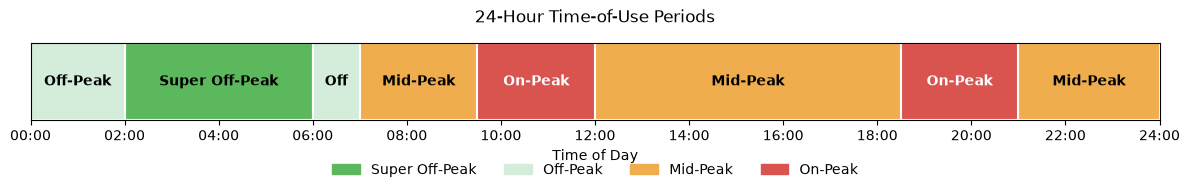

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def parse_time_to_float(time_str):
    """Converts a time string like '09:30' into a float like 9.5 for plotting."""
    h, m = map(int, time_str.split(':'))
    return h + m / 60.0

intervals = []
for category in df_tou_periods.columns:
    for time_range in df_tou_periods[category].dropna():
        start_str, end_str = time_range.split(' - ')
        start = parse_time_to_float(start_str)
        end = parse_time_to_float(end_str)

        duration = end - start
        if duration < 0: # Handle cross-midnight wrap-around if present
            duration += 24

        intervals.append((start, duration, category))

# Generate the plot
colors = {
    'Super Off-Peak': '#5cb85c',
    'Off-Peak': '#d4edda',
    'Mid-Peak': '#f0ad4e',
    'On-Peak': '#d9534f'
}

fig, ax = plt.subplots(figsize=(12, 2.5))

for start, duration, category in intervals:
    ax.broken_barh([(start, duration)], (0, 1), facecolors=colors.get(category, 'gray'), edgecolor='white', linewidth=1.5)
    mid = start + (duration / 2)

    text_color = 'white' if category == 'On-Peak' else 'black'
    label = category if duration > 1.5 else 'Off'
    ax.text(mid, 0.5, label, ha='center', va='center', color=text_color, fontsize=10, fontweight='bold')

ax.set_ylim(0, 1)
ax.set_xlim(0, 24)
ax.set_yticks([])
ax.set_xticks(range(0, 25, 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 2)])
ax.set_xlabel('Time of Day')
ax.set_title('24-Hour Time-of-Use Periods', pad=15)

patches = [mpatches.Patch(color=color, label=cat) for cat, color in colors.items()]
ax.legend(handles=patches, bbox_to_anchor=(0.5, -0.4), loc='upper center', ncol=4, frameon=False)

plt.tight_layout()
plt.show()

It can be seen above that there are certain intervals that influence the price per kVA up to 3x.

#### Information about the EV models (Standard and Premium models) is present for each user.
This information is valuable, as its connected by the model id throughout the other sheets.

Standard models:

In [5]:
df_regular_ev = pd.read_excel(
    excel_path,
    sheet_name="General Information",
    header=0,
    skiprows=3,
    nrows=15,
    usecols="T:AB",
)
df_regular_ev["Brand"] = (
    df_regular_ev["Brand"].astype(str).str.strip()
)
# remove artifact from string extraction
df_regular_ev.columns = df_regular_ev.columns.astype(str).str.strip().str.replace(".1", "", regex=False)

df_regular_ev["Model"] = df_regular_ev["Model"].astype(str).str.strip()

df_regular_ev

,Model ID,Brand,Model,Capacity (kW),Charge (kW),Discharge (kW),Efficiency,Consumption (Wh/km),Units
0,1,Dacia,Spring,27.4,27.7,27.7,0.85,119,22
1,2,Fiat,500e,36.2,64.6,64.6,0.96,120,18
2,3,Opel,Corsa-e,40.9,74.0,74.0,0.86,136,15
3,4,MG,ZS EV Standard Range,41.8,48.0,48.0,0.94,186,16
4,5,VW,ID3 pure,43.5,69.3,69.3,0.95,132,14
5,6,Renault,Zoe 52 kWh,44.0,40.6,40.6,0.81,177,14
6,7,Mazda,MX30,30.0,33.4,33.4,0.97,160,17
7,8,Citroën,e-C4,40.9,74.0,74.0,0.86,129,18
8,9,VW,ID3 pro,55.7,75.2,75.2,0.92,140,15
9,10,Opel,Mokka-e,42.9,74.0,74.0,0.90,140,19


Premium models

In [6]:
df_premium_ev = pd.read_excel(
    excel_path,
    sheet_name="General Information",
    header=0,
    skiprows=22,
    nrows=10,
    usecols="T:AB",
)
df_premium_ev["Brand"] = df_premium_ev["Brand"].astype(str).str.strip()
df_premium_ev["Model"] = df_premium_ev["Model"].astype(str).str.strip()

df_premium_ev

,Model ID,Brand,Model,Capacity (kW),Charge (kW),Discharge (kW),Efficiency,Consumption (Wh/km),Units
0,1,BMW,i4 eDrive40,80.7,121.0,121.0,0.94,137,31
1,2,Audi,Q4 e-tron 50 Quattro,76.6,92.9,92.9,0.98,186,26
2,3,Mercedes,EQB 300 4MATIC,66.5,101.6,101.6,0.95,168,24
3,4,Audi,e-tron 50 Sportback,63.6,111.7,111.7,0.93,216,19
4,5,Audi,e-tron 50,63.0,111.7,111.7,0.92,224,31
5,6,Audi,Q4 Sportback e-tron 50 quattro,76.6,92.9,92.9,0.99,182,24
6,7,Mercedes,EQB 350 4MATIC,64.8,101.6,101.6,0.93,159,27
7,8,Ford,Mach-E ER AWD,85.6,90.5,90.5,0.92,164,18
8,9,BMW,iX3,74.3,111.8,111.8,0.91,161,21
9,10,Mercedes,EQC 400,80.0,94.6,94.6,0.92,223,29


In [7]:
import itertools

reg_map = dict(
    zip(
        df_regular_ev["Model ID"],
        df_regular_ev["Brand"].str.strip() + " " + df_regular_ev["Model"].str.strip(),
    )
)
prem_map = dict(
    zip(
        df_premium_ev["Model ID"],
        df_premium_ev["Brand"].str.strip() + " " + df_premium_ev["Model"].str.strip()
    )
)
print(dict(itertools.islice(reg_map.items(), 3)))
print(dict(itertools.islice(prem_map.items(), 3)))

{1: 'Dacia Spring', 2: 'Fiat 500e', 3: 'Opel Corsa-e'}
{1: 'BMW i4 eDrive40', 2: 'Audi Q4 e-tron 50 Quattro', 3: 'Mercedes EQB 300 4MATIC'}


 By cross-referencing General Information (Player characteristics & EV catalogs), EVs, and BESS:

  • Total Households: 250 <br>
  • With PV: 200 (80%) <br>
  • With ESS: 150 (60%) <br>
  • With EVs: 250 (100% — every household is assigned 1 Regular EV as EV1 and 1 Premium EV as
  EV2) <br>

#### Household Assets (PV, ESS, EVs)
Extracted information regarding what each household posseses (i.e. PhotoVoltaic, Energy Storage Systems and Electric Vehicles)

In [8]:
df_households = pd.read_excel(
    excel_path,
    sheet_name="General Information",
    skiprows=4,
    nrows=250,
    usecols="A:C",
    header=None,
    names=["Household_ID", "Has_PV", "Has_ESS"],
)

# ESS model assignment from BESS sheet
df_bess = pd.read_excel(excel_path, sheet_name="BESS", nrows=2, header=None)
df_households["ESS_Model_ID"] = df_bess.iloc[1, 1:251].astype(int).values

# EV assignments from EVs sheet
df_evs = pd.read_excel(excel_path, sheet_name="EVs", nrows=3, header=None)
df_households["EV1_Model_ID"] = df_evs.iloc[1, 1:251].astype(int).values
df_households["EV1_Model"] = df_households["EV1_Model_ID"].map(reg_map)
df_households["EV2_Model_ID"] = df_evs.iloc[2, 1:251].astype(int).values
df_households["EV2_Model"] = df_households["EV2_Model_ID"].map(prem_map)

df_households

,Household_ID,Has_PV,Has_ESS,ESS_Model_ID,EV1_Model_ID,EV1_Model,EV2_Model_ID,EV2_Model
0,1,1,1,8,11,Peugeot e-2008 GT,3,Mercedes EQB 300 4MATIC
1,2,0,0,0,3,Opel Corsa-e,5,Audi e-tron 50
2,3,0,0,0,5,VW ID3 pure,1,BMW i4 eDrive40
3,4,1,1,6,10,Opel Mokka-e,10,Mercedes EQC 400
4,5,0,0,0,9,VW ID3 pro,1,BMW i4 eDrive40
...,...,...,...,...,...,...,...,...
245,246,1,0,0,1,Dacia Spring,10,Mercedes EQC 400
246,247,1,0,0,1,Dacia Spring,3,Mercedes EQB 300 4MATIC
247,248,0,0,0,7,Mazda MX30,4,Audi e-tron 50 Sportback
248,249,0,0,0,5,VW ID3 pure,8,Ford Mach-E ER AWD


The information on PVs is given in batches of 15 minutes across 24h. There are 96 such intervals in the course of 24h.

In [9]:
intervals_15min = [
    f"{i*15 // 60:02d}:{i*15 % 60:02d} - {(i+1)*15 // 60:02d}:{(i+1)*15 % 60:02d}"
    for i in range(96)
]
intervals_15min[45:48]

['11:15 - 11:30', '11:30 - 11:45', '11:45 - 12:00']

In [10]:
df_pv = pd.read_excel(excel_path, sheet_name="PV")
df_pv = df_pv.drop(columns=[df_pv.columns[0]])  # drop numerical index 1-96
df_pv.columns = [f"Household_{col}" for col in df_pv.columns]
df_pv.index = intervals_15min
df_pv.index.name = "Time_Interval"

df_pv

,Household_1,Household_2,Household_3,Household_4,Household_5,Household_6,Household_7,Household_8,Household_9,Household_10,...,Household_241,Household_242,Household_243,Household_244,Household_245,Household_246,Household_247,Household_248,Household_249,Household_250
Time_Interval,,,,,,,,,,,,,,,,,,,,,
00:00 - 00:15,0.0,0,0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0,0.0,0.0,0,0,0.0
00:15 - 00:30,0.0,0,0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0,0.0,0.0,0,0,0.0
00:30 - 00:45,0.0,0,0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0,0.0,0.0,0,0,0.0
00:45 - 01:00,0.0,0,0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0,0.0,0.0,0,0,0.0
01:00 - 01:15,0.0,0,0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0,0.0,0.0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22:45 - 23:00,0.0,0,0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0,0.0,0.0,0,0,0.0
23:00 - 23:15,0.0,0,0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0,0.0,0.0,0,0,0.0
23:15 - 23:30,0.0,0,0,0.0,0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0,0,0.0,0.0,0,0,0.0


In [11]:
# Filter by only PV households using df_households
pv_hh_ids = df_households.loc[df_households['Has_PV'] == 1, 'Household_ID'].tolist()
pv_cols = [f'Household_{hid}' for hid in pv_hh_ids]
pv_only_df = df_pv[pv_cols]

# Filter only daylight hours
daylight_df = pv_only_df.loc['07:45 - 08:00':'17:30 - 17:45']

print('Daylight shape:', daylight_df.shape)
print('Zeros during daylight:', (daylight_df == 0).sum().sum())

Daylight shape: (40, 200)
Zeros during daylight: 340


### PV Generation Quality Checks and Statistics
Quality checks of data integrity, daylight boundaries, and power/energy statistics.

In [12]:
total_cells = df_pv.size
total_zeros = (df_pv == 0).sum().sum()
zero_ratio = total_zeros / total_cells
null_count = df_pv.isna().sum().sum()
negative_count = (df_pv < 0).sum().sum()

print('=== 1. DATA INTEGRITY CHECKS ===')
print(f'Total Cells: {total_cells} (96 intervals x 250 households)')
print(f'Missing / Null values: {null_count}')
print(f'Negative values: {negative_count}')
print(f'Total Zeros: {total_zeros} ({zero_ratio:.2%})')

=== 1. DATA INTEGRITY CHECKS ===
Total Cells: 24000 (96 intervals x 250 households)
Missing / Null values: 0
Negative values: 0
Total Zeros: 16340 (68.08%)


In [13]:
pv_cols = pv_only_df.columns

no_pv_hh_ids = df_households.loc[df_households['Has_PV'] == 0, 'Household_ID'].tolist()
no_pv_cols = [f'Household_{hid}' for hid in no_pv_hh_ids]

zeros_no_pv = (df_pv[no_pv_cols] == 0).sum().sum()
false_positives = (df_pv[no_pv_cols] > 0).sum().sum()
false_negatives = [col for col in pv_cols if (df_pv[col] > 0).sum() == 0]

print('\n=== 2. ZERO BREAKDOWN ===')
print(f'Households without PV: {len(no_pv_cols)}')
print(f'  - Total zeros from No-PV households: {zeros_no_pv} (out of {len(no_pv_cols)*len(df_pv)})')
print(f'  - False positives (No-PV households with generation > 0): {false_positives}')
print(f'Households with PV: {len(pv_cols)}')
print(f'  - False negatives (PV households with 0 generation all day): {len(false_negatives)}')


=== 2. ZERO BREAKDOWN ===
Households without PV: 50
  - Total zeros from No-PV households: 4800 (out of 4800)
  - False positives (No-PV households with generation > 0): 0
Households with PV: 200
  - False negatives (PV households with 0 generation all day): 0


In [14]:
# 2. Temporal Profile: Daylight Window vs Nighttime
active_mask = (pv_only_df > 0).any(axis=1)
active_intervals = active_mask[active_mask].index.tolist()
first_interval = active_intervals[0]
last_interval = active_intervals[-1]
daylight_intervals_count = len(active_intervals)
daylight_hours = daylight_intervals_count * 15 / 60

nighttime_intervals = active_mask[~active_mask].index.tolist()
zeros_nighttime = (df_pv.loc[nighttime_intervals, pv_cols] == 0).sum().sum()
midday_zeros = (df_pv.loc['08:30 - 08:45':'17:00 - 17:15', pv_cols] == 0).sum().sum()

print('=== 3. TEMPORAL PROFILE ===')
print(f'Active Generation Window: {first_interval} to {last_interval}')
print(f'Daylight Intervals: {daylight_intervals_count} / 96 ({daylight_hours:.1f} hours)')
print(f'Nighttime Intervals: {len(nighttime_intervals)} / 96 ({len(nighttime_intervals)*15/60:.1f} hours)')
print(f'Nighttime Zeros (for 200 PV households): {zeros_nighttime} (out of {len(nighttime_intervals)*len(pv_cols)})')
print(f'Midday Zero Dropouts (08:30 to 17:00): {midday_zeros}')

=== 3. TEMPORAL PROFILE ===
Active Generation Window: 07:45 - 08:00 to 17:30 - 17:45
Daylight Intervals: 40 / 96 (10.0 hours)
Nighttime Intervals: 56 / 96 (14.0 hours)
Nighttime Zeros (for 200 PV households): 11200 (out of 11200)
Midday Zero Dropouts (08:30 to 17:00): 0


In [15]:
# 3. Power & Energy Metrics
# Energy (kWh) = Power (kW) * 0.25h
daily_energy_kwh = pv_only_df.sum(axis=0) * 0.25
peak_power_kw = pv_only_df.max(axis=0)

community_profile = pv_only_df.sum(axis=1)
community_peak_power = community_profile.max()
community_peak_interval = community_profile.idxmax()
community_total_energy = daily_energy_kwh.sum()

print('=== 4. POWER & ENERGY METRICS ===')
print(f'Community Peak Power: {community_peak_power:.2f} kW (at interval {community_peak_interval})')
print(f'Community Daily Energy: {community_total_energy:.2f} kWh/day')

stats_df = pd.DataFrame({
    'Peak Power (kW)': peak_power_kw.describe()[['min', '25%', '50%', 'mean', '75%', 'max']],
    'Daily Energy (kWh)': daily_energy_kwh.describe()[['min', '25%', '50%', 'mean', '75%', 'max']]
})
stats_df.round(2)

=== 4. POWER & ENERGY METRICS ===
Community Peak Power: 561.27 kW (at interval 13:00 - 13:15)
Community Daily Energy: 2390.86 kWh/day


,Peak Power (kW),Daily Energy (kWh)
min,0.12,0.40
25%,1.89,6.17
50%,2.61,9.07
mean,3.51,11.95
75%,5.04,17.59
max,9.84,34.21


#### Visualization: Zeros Disappearing at Sunrise & Reappearing at Sunset
The dual-panel plot below illustrates:
1. **Top panel**: The count of zero vs active generating households across time, highlighting the 08:30 - 17:15 core daylight window where all 200 PV households are active without dropouts.
2. **Bottom panel**: A binary activity raster of all 200 PV households (sorted by sunrise activation time), visually displaying the staggered sunrise ramp-up and sunset cut-off.

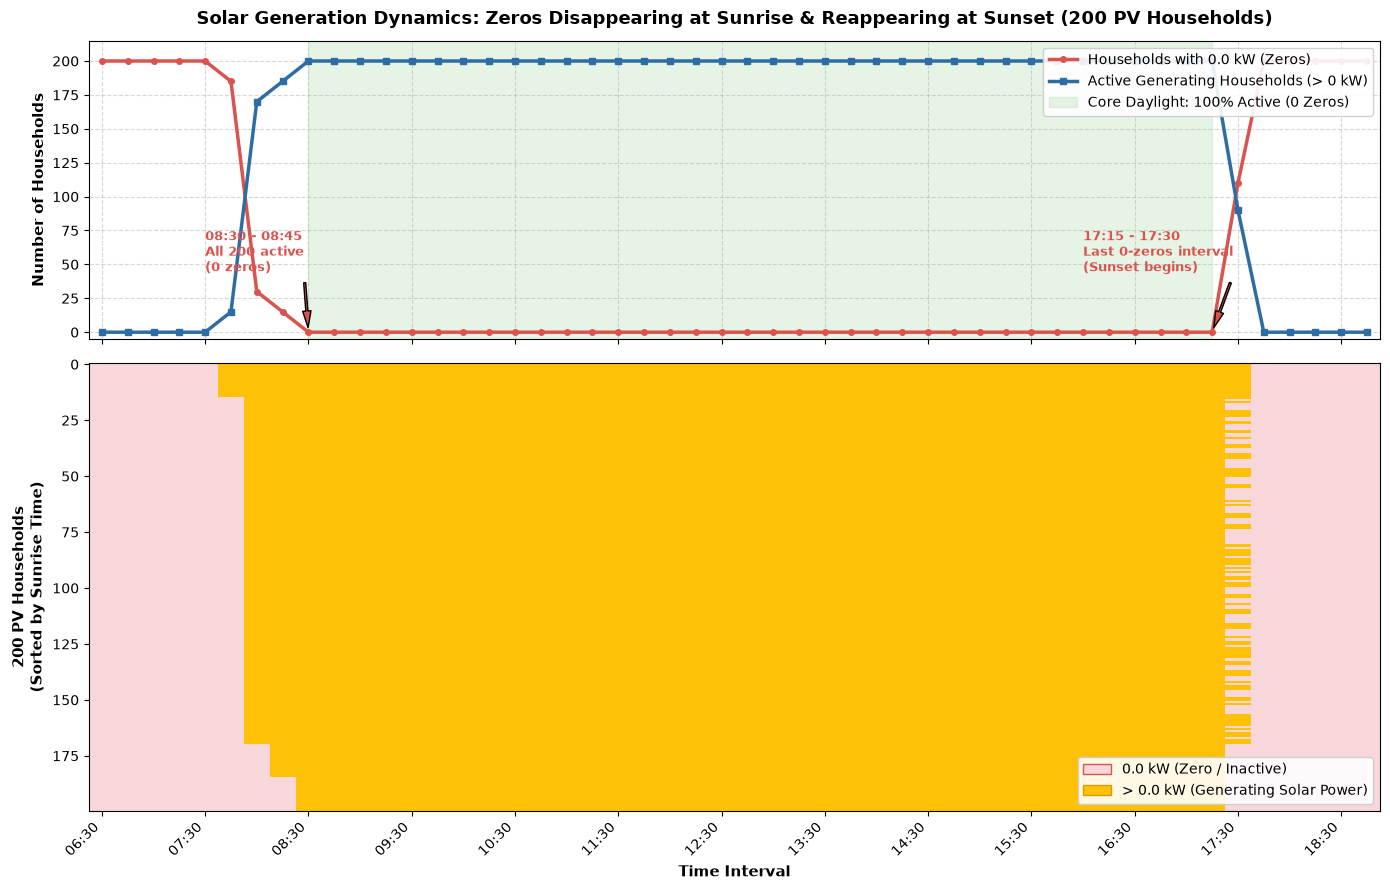

In [16]:
### Plotting of active/inactive periods throughtout the day
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import numpy as np

# Daytime window: 06:30 to 18:45 (intervals 26 to 75)
day_window = intervals_15min[26:76]
pv_day = pv_only_df.loc[day_window]

zero_counts = (pv_day == 0).sum(axis=1)
active_counts = (pv_day > 0).sum(axis=1)

# Sort households by their sunrise onset (first non-zero index)
first_active = (pv_day > 0).idxmax(axis=0)
sorted_hh = first_active.sort_values().index.tolist()
binary_matrix = (pv_day[sorted_hh].T > 0).astype(int)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [1.2, 1.8]})

# Panel 1: Aggregated Counts
x = np.arange(len(day_window))
ax1.plot(x, zero_counts.values, color='#d9534f', linewidth=2.5, marker='o', markersize=4, label='Households with 0.0 kW (Zeros)')
ax1.plot(x, active_counts.values, color='#2e6da4', linewidth=2.5, marker='s', markersize=4, label='Active Generating Households (> 0 kW)')

# Highlight core midday window (08:30 to 17:15)
idx_0830 = day_window.index('08:30 - 08:45')
idx_1715 = day_window.index('17:15 - 17:30')
ax1.axvspan(idx_0830, idx_1715, color='#5cb85c', alpha=0.15, label='Core Daylight: 100% Active (0 Zeros)')

# Annotations
ax1.annotate('08:30 - 08:45\nAll 200 active\n(0 zeros)', 
             xy=(idx_0830, 0), xytext=(idx_0830 - 4, 45),
             arrowprops=dict(facecolor='#d9534f', shrink=0.08, width=1.5, headwidth=6),
             fontsize=9, fontweight='bold', color='#d9534f')

ax1.annotate('17:15 - 17:30\nLast 0-zeros interval\n(Sunset begins)', 
             xy=(idx_1715, 0), xytext=(idx_1715 - 5, 45),
             arrowprops=dict(facecolor='#d9534f', shrink=0.08, width=1.5, headwidth=6),
             fontsize=9, fontweight='bold', color='#d9534f')

ax1.set_ylabel('Number of Households', fontsize=11, fontweight='bold')
ax1.set_title('Solar Generation Dynamics: Zeros Disappearing at Sunrise & Reappearing at Sunset (200 PV Households)', fontsize=13, fontweight='bold', pad=12)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.set_ylim(-5, 215)
ax1.legend(loc='upper right', framealpha=0.9)

# Panel 2: Raster / Heatmap of the 200 Households
cmap = ListedColormap(['#f8d7da', '#ffc107'])
cax = ax2.imshow(binary_matrix.values, aspect='auto', cmap=cmap, interpolation='nearest')

ax2.set_ylabel('200 PV Households\n(Sorted by Sunrise Time)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Time Interval', fontsize=11, fontweight='bold')

# X-axis ticks (every 4 intervals = 1 hour)
tick_indices = np.arange(0, len(day_window), 4)
ax2.set_xticks(tick_indices)
ax2.set_xticklabels([day_window[i].split(' - ')[0] for i in tick_indices], rotation=45, ha='right')

legend_elements = [
    Patch(facecolor='#f8d7da', edgecolor='#d9534f', label='0.0 kW (Zero / Inactive)'),
    Patch(facecolor='#ffc107', edgecolor='#d39e00', label='> 0.0 kW (Generating Solar Power)')
]
ax2.legend(handles=legend_elements, loc='lower right', framealpha=0.9)

plt.tight_layout()
plt.show()

Computing Net load per household: